# 04 Exhibits

**Resultado:** tres gráficos y una animación que cuentan dónde pierden energía las plantas, en `05_resultados/Exhibits`.

**Índice**

1. Cargar
2. Historia
3. Gráficos
4. Animación

## 0. Librerías y rutas

In [1]:
# ── Librerías ───
import io
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import to_rgb
from pathlib import Path
from PIL import Image

# ── Rutas del proyecto (el notebook vive en 03_notebooks) ───
RAIZ = Path.cwd().parent
ORIGINALES = RAIZ / '02_datos' / '01_Originales'
RESULTADOS = RAIZ / '05_resultados'
SALIDA = RESULTADOS / 'Exhibits'
SALIDA.mkdir(exist_ok = True)

# ── Estilo: grises y un solo color de acento ───
ROJO = '#C0392B'
GRIS = '#8C8C8C'
OSCURO = '#333333'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['font.size'] = 11

## 1. Cargar

Las dos plantas en tramos de 15 minutos. Un inversor está caído cuando marca 0 kW de potencia AC mientras la mediana de su planta, en ese mismo instante, es positiva. Es el mismo criterio del análisis.

In [2]:
# ── Leer cada planta con su formato de fecha ───
tablas = []
for numero in [1, 2]:
    d = pd.read_csv(ORIGINALES / ('Planta' + str(numero) + '_Generacion.csv'))
    d['planta'] = 'Planta ' + str(numero)
    if numero == 1:
        d['t'] = pd.to_datetime(d['fecha_hora'], format = '%d-%m-%Y %H:%M')
    else:
        d['t'] = pd.to_datetime(d['fecha_hora'])
    tablas.append(d)
g = pd.concat(tablas)

# ── Criterio de caído ───
g['ref'] = g.groupby(['planta', 't'])['potencia_ac_kw'].transform('median')
g['caido'] = (g['ref'] > 0) & (g['potencia_ac_kw'] <= 0)
g['fecha'] = g['t'].dt.normalize()
g[['planta', 'id_inversor', 'fecha', 'caido']].groupby('planta')['caido'].sum() * 0.25

planta
Planta 1     20.5
Planta 2    859.0
Name: caido, dtype: float64

## 2. Historia

Los títulos, en orden.

1. Planta 2 sumó 859 inversor-horas caídas en 34 días; Planta 1, 20,5.
2. El 7 de junio, hasta 10 de 22 inversores de Planta 2 estuvieron en cero a la vez al mediodía.
3. Cinco inversores de Planta 2 pararon entre 54 y 74 horas; el peor de Planta 1, 5,75.

## 3. Gráficos

### EX1 · Inversor-horas caídas por día

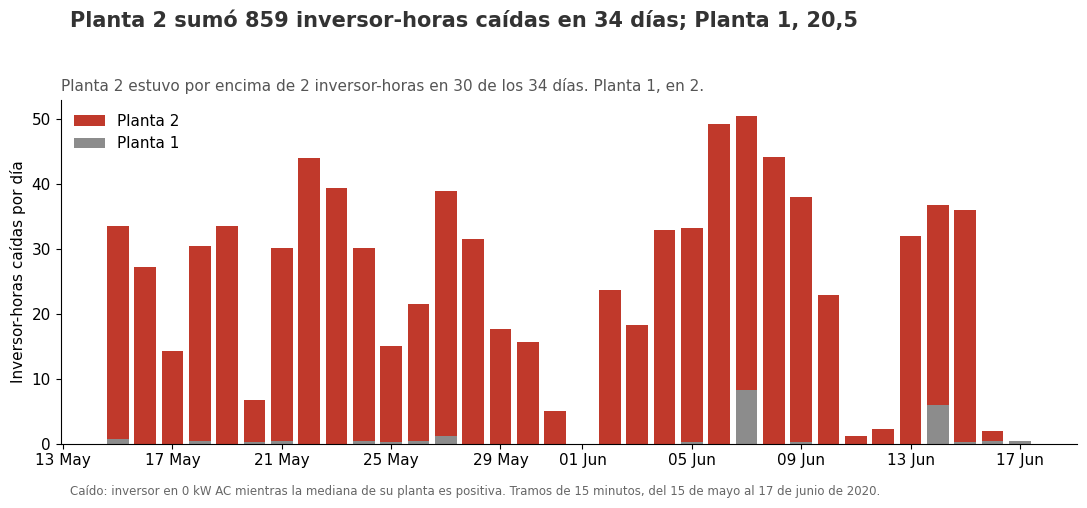

In [3]:
# ── EX1: inversor-horas caídas por día ───
d = g.groupby(['planta', 'fecha'])['caido'].sum().mul(0.25).unstack(0)

fig, ax = plt.subplots(figsize = (11, 5))
ax.bar(d.index, d['Planta 2'], color = ROJO, width = 0.8, label = 'Planta 2')
ax.bar(d.index, d['Planta 1'], color = GRIS, width = 0.8, label = 'Planta 1')
ax.set_ylabel('Inversor-horas caídas por día')
ax.legend(frameon = False, loc = 'upper left')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
fig.suptitle('Planta 2 sumó 859 inversor-horas caídas en 34 días; Planta 1, 20,5', x = 0.07, ha = 'left', fontsize = 15, fontweight = 'bold', color = OSCURO)
ax.set_title('Planta 2 estuvo por encima de 2 inversor-horas en 30 de los 34 días. Planta 1, en 2.', loc = 'left', fontsize = 11, color = '#555555')
fig.text(0.07, 0.01, 'Caído: inversor en 0 kW AC mientras la mediana de su planta es positiva. Tramos de 15 minutos, del 15 de mayo al 17 de junio de 2020.', fontsize = 8.5, color = '#666666')
fig.tight_layout(rect = [0, 0.03, 1, 0.95])
fig.savefig(SALIDA / 'EX1_inversor_horas_por_dia.png', dpi = 200, bbox_inches = 'tight')
plt.show()

### EX2 · El 7 de junio, hora por hora

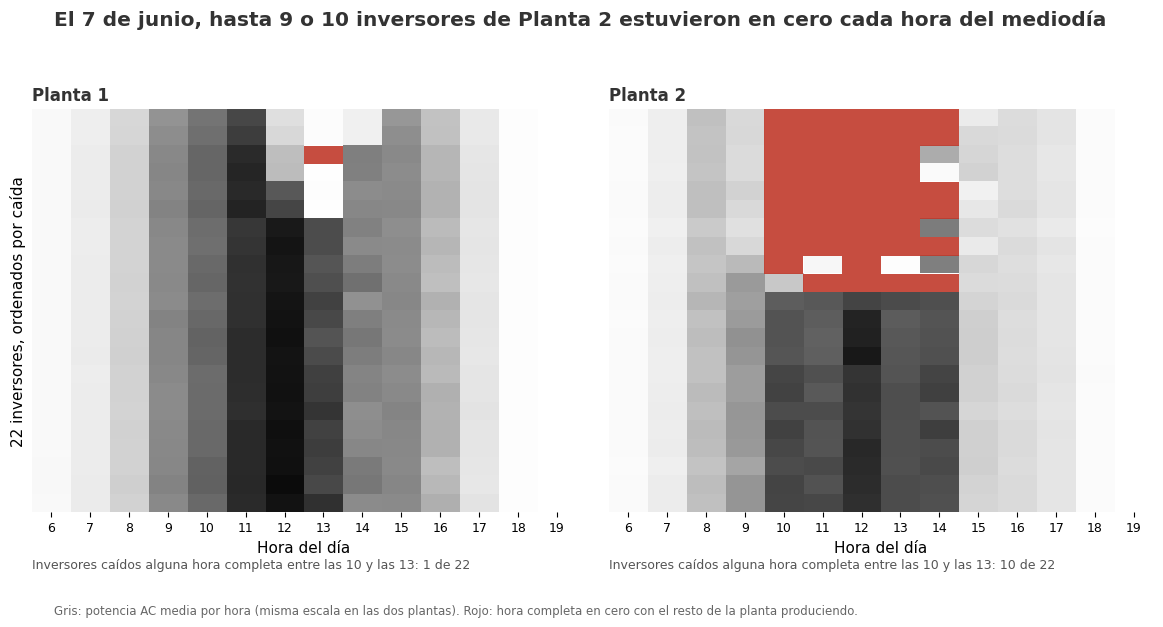

In [4]:
# ── EX2: potencia AC por hora e inversor el 7 de junio ───
dia = g[g['fecha'] == '2020-06-07'].copy()
dia['h'] = dia['t'].dt.hour
vmax = dia['potencia_ac_kw'].max()

fig, axs = plt.subplots(1, 2, figsize = (12, 6.2))
for ax, planta in zip(axs, ['Planta 1', 'Planta 2']):
    x = dia[dia['planta'] == planta]
    m = x.pivot_table(index = 'id_inversor', columns = 'h', values = 'potencia_ac_kw', aggfunc = 'mean').loc[:, 6:19]
    c = x.pivot_table(index = 'id_inversor', columns = 'h', values = 'caido', aggfunc = 'mean').loc[:, 6:19]
    orden = m.loc[:, 10:13].mean(axis = 1).sort_values().index
    m = m.loc[orden]
    c = c.loc[orden]
    ax.imshow(m.values, aspect = 'auto', cmap = 'Greys', vmin = 0, vmax = vmax)
    # Rojo: hora completa en cero con el resto de la planta produciendo
    for i in range(c.shape[0]):
        for j in range(c.shape[1]):
            if c.values[i, j] >= 0.99:
                ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, color = ROJO, alpha = 0.9, lw = 0))
    ax.set_xticks(range(14))
    ax.set_xticklabels(range(6, 20), fontsize = 9)
    ax.set_yticks([])
    ax.set_xlabel('Hora del día')
    ax.set_title(planta, loc = 'left', fontsize = 12, color = OSCURO, fontweight = 'bold')
    ax.spines[:].set_visible(False)
    k = int((c.loc[:, 10:13] >= 0.99).any(axis = 1).sum())
    ax.text(0.0, -0.14, 'Inversores caídos alguna hora completa entre las 10 y las 13: ' + str(k) + ' de 22', transform = ax.transAxes, fontsize = 9, color = '#555555')
axs[0].set_ylabel('22 inversores, ordenados por caída')
fig.suptitle('El 7 de junio, hasta 9 o 10 inversores de Planta 2 estuvieron en cero cada hora del mediodía', x = 0.05, ha = 'left', fontsize = 14.5, fontweight = 'bold', color = OSCURO)
fig.text(0.05, 0.005, 'Gris: potencia AC media por hora (misma escala en las dos plantas). Rojo: hora completa en cero con el resto de la planta produciendo.', fontsize = 8.5, color = '#666666')
fig.tight_layout(rect = [0, 0.03, 1, 0.94])
fig.savefig(SALIDA / 'EX2_heatmap_7_junio.png', dpi = 200, bbox_inches = 'tight')
plt.show()

### EX3 · Los cinco inversores con más energía perdida

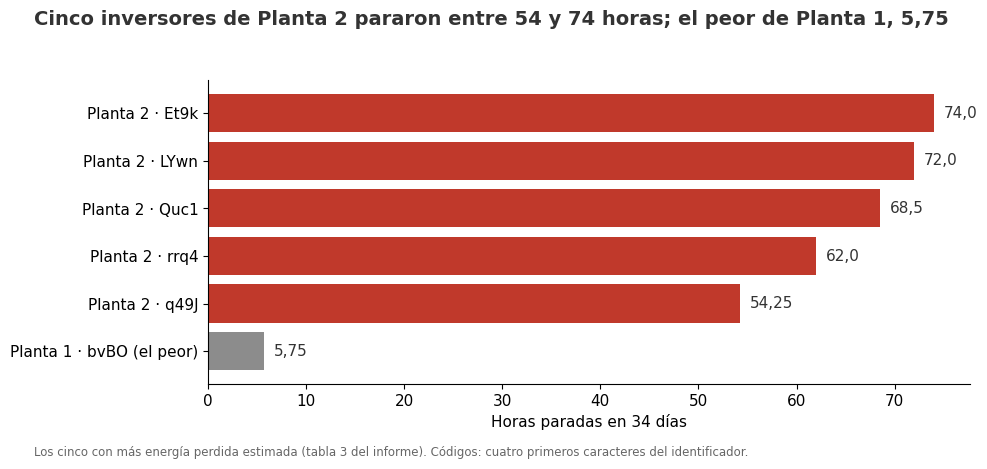

In [5]:
# ── EX3: horas paradas de los cinco inversores de Planta 2 con más energía perdida ───
ids = ['Et9kgGMDl729KT4', 'LYwnQax7tkwH5Cb', 'Quc1TzYxW2pYoWX', 'rrq4fwE8jgrTyWY', 'q49J1IKaHRwDQnt']
horas = g.groupby('id_inversor')['caido'].sum() * 0.25
peor_p1 = g[g['planta'] == 'Planta 1'].groupby('id_inversor')['caido'].sum().mul(0.25).sort_values().index[-1]

etiquetas = []
valores = []
for i in ids:
    etiquetas.append('Planta 2 · ' + i[:4])
    valores.append(horas[i])
etiquetas.append('Planta 1 · ' + peor_p1[:4] + ' (el peor)')
valores.append(horas[peor_p1])

fig, ax = plt.subplots(figsize = (10, 4.6))
colores = [ROJO] * 5 + [GRIS]
posiciones = list(range(6))[::-1]
barras = ax.barh(posiciones, valores, color = colores)
ax.set_yticks(posiciones)
ax.set_yticklabels(etiquetas)
for barra, v in zip(barras, valores):
    ax.text(v + 1, barra.get_y() + barra.get_height() / 2, str(v).replace('.', ','), va = 'center', fontsize = 11, color = OSCURO)
ax.set_xlabel('Horas paradas en 34 días')
fig.suptitle('Cinco inversores de Planta 2 pararon entre 54 y 74 horas; el peor de Planta 1, 5,75', x = 0.04, ha = 'left', fontsize = 14, fontweight = 'bold', color = OSCURO)
fig.text(0.04, 0.01, 'Los cinco con más energía perdida estimada (tabla 3 del informe). Códigos: cuatro primeros caracteres del identificador.', fontsize = 8.5, color = '#666666')
fig.tight_layout(rect = [0, 0.03, 1, 0.94])
fig.savefig(SALIDA / 'EX3_top_inversores.png', dpi = 200, bbox_inches = 'tight')
plt.show()

## 4. Animación

El 7 de junio entre las 6 y las 19 horas, cada 30 minutos. Un cuadro por inversor.

In [6]:
# ── EX4: animación del 7 de junio ───
d7 = g[g['fecha'] == '2020-06-07']
tramos = sorted(d7['t'].unique())
tramos = [t for t in tramos if 6 <= pd.Timestamp(t).hour < 19]

mats = {}
for planta in ['Planta 1', 'Planta 2']:
    x = d7[d7['planta'] == planta]
    orden = x[x['t'].dt.hour.between(10, 13)].groupby('id_inversor')['caido'].mean().sort_values().index
    ac = x.pivot(index = 'id_inversor', columns = 't', values = 'potencia_ac_kw').reindex(orden)
    ca = x.pivot(index = 'id_inversor', columns = 't', values = 'caido').reindex(orden)
    mats[planta] = (ac, ca)

cuadros = []
for t in tramos[::2]:
    fig, axs = plt.subplots(1, 2, figsize = (8, 4.6), dpi = 90)
    for ax, planta in zip(axs, ['Planta 1', 'Planta 2']):
        ac, ca = mats[planta]
        v = ac[t].values.reshape(2, 11)
        c = ca[t].fillna(False).astype(bool).values.reshape(2, 11)
        rgb = np.zeros((2, 11, 3))
        for i in range(2):
            for j in range(11):
                if np.isnan(v[i, j]):
                    rgb[i, j] = (0.85, 0.85, 0.85)
                elif c[i, j]:
                    rgb[i, j] = to_rgb(ROJO)
                else:
                    s = 0.80 - 0.45 * min(v[i, j] / vmax, 1)
                    rgb[i, j] = (s, s, s)
        ax.imshow(rgb, aspect = 'equal')
        ax.set_xticks([])
        ax.set_yticks([])
        for lado in ax.spines.values():
            lado.set_visible(False)
        ax.set_xticks(np.arange(-0.5, 11, 1), minor = True)
        ax.set_yticks(np.arange(-0.5, 2, 1), minor = True)
        ax.grid(which = 'minor', color = 'white', lw = 3)
        ax.tick_params(which = 'minor', length = 0)
        n = int(c.sum())
        ax.set_title(planta + ': ' + str(n) + ' caídos', fontsize = 13, color = ROJO if n > 0 else OSCURO, fontweight = 'bold', loc = 'left')
    hora = pd.Timestamp(t).strftime('%H:%M')
    fig.suptitle('7 de junio de 2020 · ' + hora, x = 0.06, ha = 'left', fontsize = 15, fontweight = 'bold', color = OSCURO)
    fig.text(0.06, 0.04, 'Cada cuadro es un inversor. Rojo: en cero con el resto de su planta produciendo. Gris: más oscuro, más potencia.', fontsize = 7.5, color = '#666666')
    fig.subplots_adjust(top = 0.78, bottom = 0.12, wspace = 0.1)
    buf = io.BytesIO()
    fig.savefig(buf, format = 'png')
    plt.close(fig)
    buf.seek(0)
    cuadros.append(Image.open(buf).convert('P', palette = Image.ADAPTIVE))

cuadros[0].save(SALIDA / 'EX4_7_junio_animado.gif', save_all = True, append_images = cuadros[1:], duration = 140, loop = 0, optimize = True)
len(cuadros)

26